# Tiamat

## Introdução

Este notebook apresenta o dataset *Infrared Thermography Temperature*, originário do banco de dados *UCI Irvine Machine Learning Repository*. Ele apresenta um conjuntos de dados como temperaturas do rosto, idade e gênero que podem permitir aferir a temperatura bocal de dois *targets*, `avelOralF` e `aveOralM` (que foi definido como o *target* neste notebook). 

Para lidar com esse conjunto de dados,  foi realizada um fluxo de ajuste de hiperparâmetros via Optuna aplicado a cinco modelos de regressão: Ridge, k-NN, Árvore de decisão, Floresta aleatória e Gradiente boosting, avaliados por validação cruzada com foco na minimização do RMSE. 


## Dataset

O conjunto de dados utilizado refere-se à Temperatura por termografia infravermelha (*Infrared Thermography Temperature*), que contém "temperaturas obtidas a partir de diversos pontos em imagens infravermelhas de pacientes, acrescido das temperaturas orais medidas para cada indivíduo."[1]. 

Primeiro é necessário instalar o repositório, como foi feito na célula seguinte:

In [1]:
!pip install ucimlrepo

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


E em seguida o conjunto de dados:

### Imports

In [2]:
import optuna.visualization as vis
import pandas as pd
import math
import numpy as np
import optuna
import matplotlib.pyplot as plt
import statsmodels.api as sm
import seaborn as sns

optuna.logging.set_verbosity(optuna.logging.WARNING)

from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.compose import ColumnTransformer, make_column_transformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.metrics import root_mean_squared_error
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from ucimlrepo import fetch_ucirepo
from optuna import create_study
from functools import partial

In [3]:
infrared_thermography_temperature = fetch_ucirepo(id=925) 
  
 
X = infrared_thermography_temperature.data.features 
Y = infrared_thermography_temperature.data.targets 
  
print(infrared_thermography_temperature.metadata) 
print(infrared_thermography_temperature.variables) 

{'uci_id': 925, 'name': 'Infrared Thermography Temperature', 'repository_url': 'https://archive.ics.uci.edu/dataset/925/infrared+thermography+temperature+dataset', 'data_url': 'https://archive.ics.uci.edu/static/public/925/data.csv', 'abstract': 'The Infrared Thermography Temperature Dataset contains temperatures read from various locations of inferred images about patients, with the addition of oral temperatures measured for each individual. The 33 features consist of gender, age, ethnicity, ambiant temperature, humidity, distance, and other temperature readings from the thermal images. The dataset is intended to be used in a regression task to predict the oral temperature using the environment information as well as the thermal image readings. ', 'area': 'Health and Medicine', 'tasks': ['Regression'], 'characteristics': ['Tabular'], 'num_instances': 1020, 'num_features': 33, 'feature_types': ['Real', 'Categorical'], 'demographics': ['Gender', 'Age', 'Ethnicity'], 'target_col': ['aveO

Como foi possível observar, o Dataset equivale à `infrared_thermography_temperature`, os atributos agora são equivalentes ao Dataframe `X` e os Target ao `Y`.

## Divisão Treino e Teste

A divisão entre dados de treino e teste é de extrema importância para que os algoritmo não "memorize" os resultados e os resultados do modelo não sejam superestimados.

Para esse teste, será utilizado um total de 20% do conjunto de dados, de um total de 1020 indivíduos distintos. Essa porcentagem se baseou nos valores usuais de divisão treino e teste considerando a quantidade de indivíduos distintos, observada. Além disso, o valor da semente aleatória é fixo para que o resultado seja reprodutível.

In [4]:
atributos = X
target = Y["aveOralM"]


X_treino, X_teste, y_treino, y_teste = train_test_split(
    atributos, target, test_size= 0.2, random_state= 10806
)

print(X_treino.shape)
print(X_teste.shape)
print(y_treino.shape)
print(y_teste.shape)

(816, 33)
(204, 33)
(816,)
(204,)


Ao aplicar o `.shape`, é confirmado que a divisão 80/20 foi aplicada adequadamente pelo código. Isso é explicado pois, 80% de 1020 indivíduos equivale a 816, como é observado pelo número de linhas no `print(X_treino.shape)` e no `print(y_treino.shape)`. Os dados dos outros 204 indivíduos (20%) serão utilizados futuramente para teste.

## Análise exploratória dos dados

Para realizar a análise dos dados, primeiro será aplicado o comando `describe()` em cada Dataframe, permitindo uma melhor observação de todo o material disponível. Com esses resultados é possível analisar e criar gráficos didáticos.

In [5]:
df_inteiro = infrared_thermography_temperature.data.original

df_inteiro["SubjectID"].describe()

count          1020
unique         1020
top       180514-01
freq              1
Name: SubjectID, dtype: object

### Targets

In [6]:
y_treino.describe()

count    816.000000
mean      37.032341
std        0.524772
min       35.540000
25%       36.740000
50%       36.940000
75%       37.140000
max       40.340000
Name: aveOralM, dtype: float64

Como pode-se observar, o conjunto de dados apresenta dois Targets, `aveOralF` e `aveOralM`. Para pode avaliar melhor as diferenças entre eles e qual dos dois é mais adequado para esse projeto, será gerado um conjunto de gráficos, permitindo essa análise.

In [7]:
df_treino = Y.loc[X_treino.index]
df_treino.shape

(816, 2)

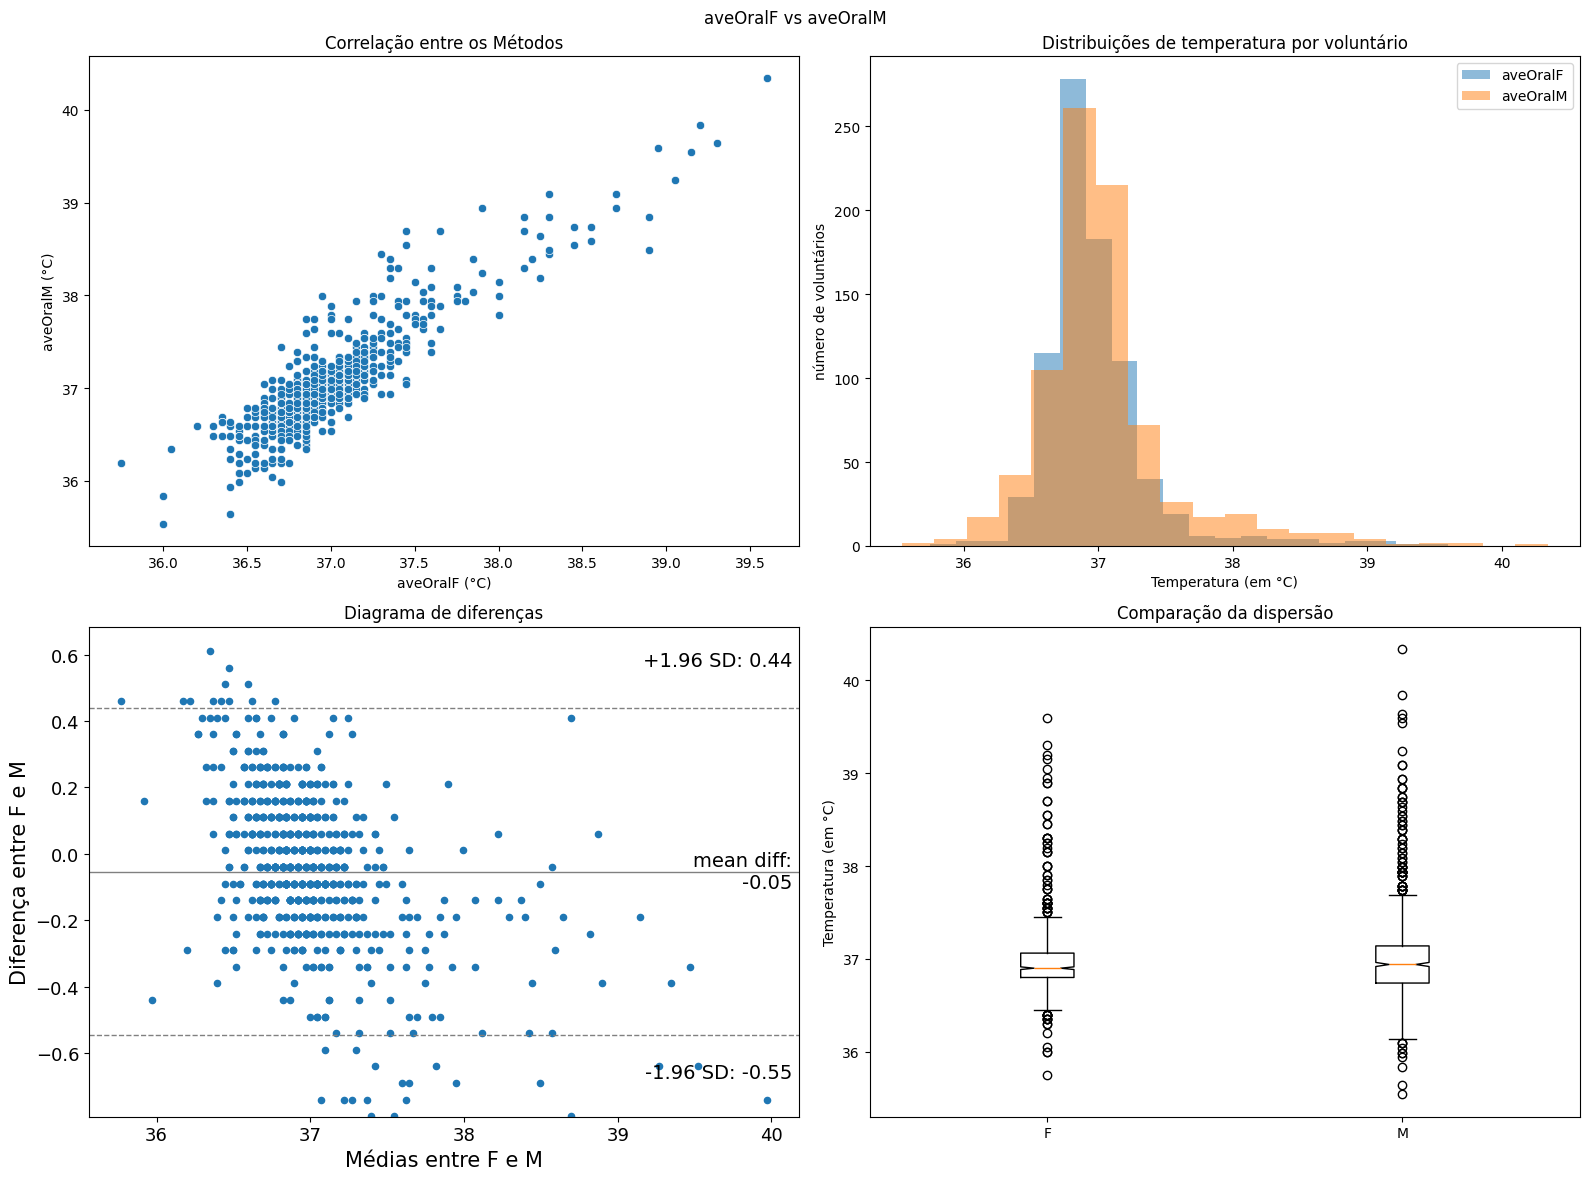

In [8]:
fig, axes = plt.subplots(2, 2, figsize = (16, 12))
fig.suptitle("aveOralF vs aveOralM")

sns.scatterplot(x = df_treino["aveOralF"], y = df_treino["aveOralM"], ax = axes[0,0])
Target_F = df_treino["aveOralF"]
Target_M = df_treino["aveOralM"]
axes[0, 0].set_title("Correlação entre os Métodos")
axes[0, 0].set_xlabel('aveOralF (°C)')
axes[0, 0].set_ylabel('aveOralM (°C)')


dist1 = Target_F
dist2 = Target_M
axes[0, 1].hist(dist1, bins = 20, alpha = 0.5, label = ("aveOralF"))
axes[0, 1].hist(dist2, bins = 20, alpha = 0.5, label = ("aveOralM"))
axes[0, 1].set_title("Distribuições de temperatura por voluntário")
axes[0, 1].set_xlabel('Temperatura (em °C)')
axes[0, 1].set_ylabel('número de voluntários')
axes[0, 1].legend()


data = df_treino
axes[1, 1].boxplot(data, notch=True, tick_labels=['F', 'M'])
axes[1, 1].set_title('Comparação da dispersão')
axes[1, 1].set_ylabel("Temperatura (em °C)")

sm.graphics.mean_diff_plot(dist1, dist2, sd_limit=1.96, ax = axes[1, 0])
axes[1, 0].set_title("Diagrama de diferenças")
axes[1, 0].set_xlabel('Médias entre F e M')
axes[1, 0].set_ylabel('Diferença entre F e M')


plt.show()

O primeiro gráfico é conhecido como `scatterplot`, ele compara as diferentes medições através dos pontos, como é possível observar, os pontos aprensentam tendência crescente, forma linear e intensidade forte. Isso indica que os targets são muito correlacionados, já que ao aumentar um, o outro também aumenta.

O histograma revela certas diferenças entre os targets de forma mais visível, ao apresentar que apesar de ambos apresentarem concentração de valores ao redor do ponto central, em 37 graus Celsius, o aveOralM revela uma cauda tendendo para a direita maior e mais intensa que aveOralF. Além disso, M apresenta maior número de voluntários à direita do ponto central que F.

O `boxplot` revela informações como centro, dispersão, assimetria e valores discrepantes. Com isso, observa-se que as medianas são similares, mas a dispersão de aveOralM é maior que a de aveOralF, como observado anteriormente, M também apresenta um valor maior de outliers.

Por fim, o gráfico de Bland-Altman, conhecido como diagrama de diferença, apresenta o sinal e valor da diferença média em °C, limites de concordância e se o espalhamento muda com a temperatura. Ele mostra que a diferença de médias é muito pequena, de apenas -0,05. 

Assim, ao escolher o target aveOralM, por ser mais preciso nas medições, como é informado pela documentação do próprio dataset, entende-se também que ele é mais disperso e tende a ser mais difícil de prever que aveOralF.

### Argumentos

O primeiro ponto para avaliar os atributos é verificar quais são numéricos e quais são catergóricos. Para isso, será utilizado o comando `info()` de `pandas`, que revela o `Dtype` de cada feature do Dataset.

In [9]:
X_treino.info()

<class 'pandas.core.frame.DataFrame'>
Index: 816 entries, 464 to 518
Data columns (total 33 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Gender       816 non-null    object 
 1   Age          816 non-null    object 
 2   Ethnicity    816 non-null    object 
 3   T_atm        816 non-null    float64
 4   Humidity     816 non-null    float64
 5   Distance     814 non-null    float64
 6   T_offset1    816 non-null    float64
 7   Max1R13_1    816 non-null    float64
 8   Max1L13_1    816 non-null    float64
 9   aveAllR13_1  816 non-null    float64
 10  aveAllL13_1  816 non-null    float64
 11  T_RC1        816 non-null    float64
 12  T_RC_Dry1    816 non-null    float64
 13  T_RC_Wet1    816 non-null    float64
 14  T_RC_Max1    816 non-null    float64
 15  T_LC1        816 non-null    float64
 16  T_LC_Dry1    816 non-null    float64
 17  T_LC_Wet1    816 non-null    float64
 18  T_LC_Max1    816 non-null    float64
 19  RCC1       

Esse resultado apresenta uma avaliação das 33 *features* desse conjunto de dados. É possível observar também que há apenas 3 atributos categóricos, já que apresentam `object` como `Dtype`, o que indica que sua informação é um texto. Já os outros 30 atributos são numéricos, é o que revela o `float64`, pois informa que naquela coluna há números decimais.

Agora, serão avaliados os atributos categóricos e como interagem com o atributo decidido (aveOralM).


#### Atributos categóricos 

In [10]:
X_treino["Gender"].value_counts()

Gender
Female    483
Male      333
Name: count, dtype: int64

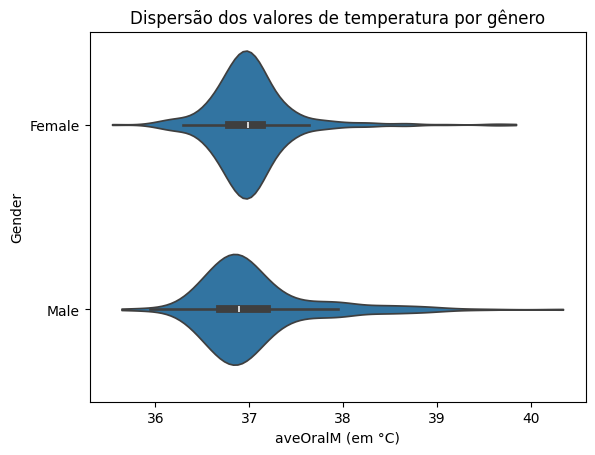

In [11]:
violin = sns.violinplot(x = y_treino, y = X_treino["Gender"], cut = 0)

violin.set_xlabel("aveOralM (em °C)")
violin.set_title("Dispersão dos valores de temperatura por gênero");

O `violinplot` permite avaliar se os grupos do atributo categórico `Gender` apresentam diferenças no aveOralM. Com ele é possível visualizar as diferenças entre os pacientes do gênero feminino e masculino, como: há mais mulheres que homens participando das medições, como visto com o `value_counts`. Além disso, a cauda do `Male` alcança aproximadamente 40,7°C, diferente de `Female` que não passa de 40°C.

In [12]:
X_treino["Age"].describe()

count       816
unique        8
top       18-20
freq        426
Name: Age, dtype: object

In [13]:
X_treino["Age"].value_counts()

Age
18-20    426
21-25    286
26-30     54
31-40     23
51-60      9
21-30      9
41-50      6
>60        3
Name: count, dtype: int64

As idades são definidas por um total de 8 grupos distintos, separados por faixa etária. A maior concentração de pacientes se encontra na menor faixa etária (18-20 anos), sendo um total de 426, enquanto apenas 3 indivíduos possuem mais que 60 anos. Um problema observado é a existência da faixa `21-30`, sendo que existem as faixas `21-25` e `26-30`, o que ainda representa um conjunto de indivíduos distintos, mas gera certa sobreposição que não é explicada pelo material.

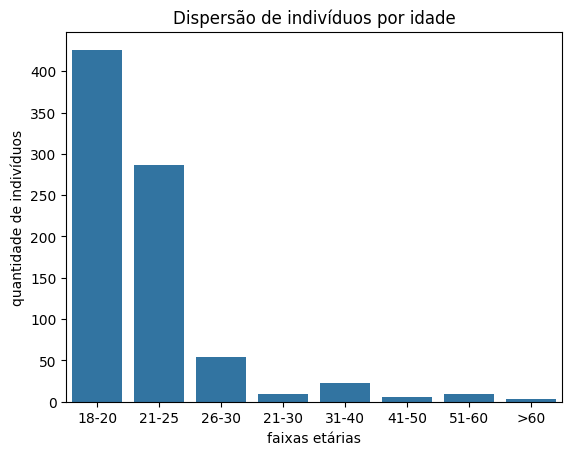

In [14]:
ordem_idade = ["18-20", "21-25", "26-30", "21-30", "31-40", "41-50", "51-60", ">60"]

idade = sns.countplot(x = X_treino["Age"], order = ordem_idade)

idade.set_xlabel("faixas etárias")
idade.set_ylabel("quantidade de indivíduos")
idade.set_title("Dispersão de indivíduos por idade");

O gráfico de barras confirma a dispersão decrescente das idades dos indivíduos que tiveram suas temperaturas medidas, conforme foi observado com o `value_counts`. Assim, é notório que a grande maioria dos pacientes se encontra na faixa 18-20 anos.

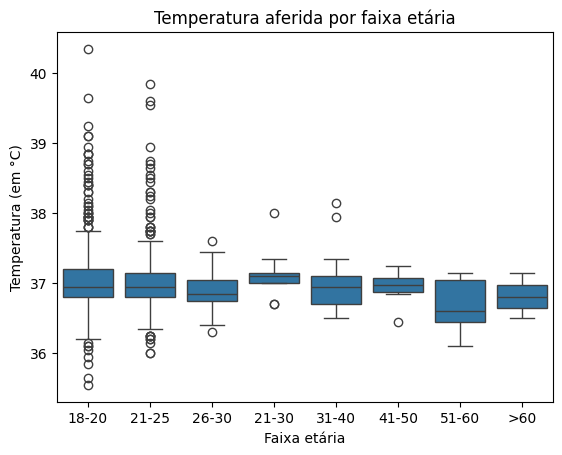

In [15]:
box = sns.boxplot(x = X_treino["Age"],y = y_treino, order = ordem_idade)

box.set_xlabel("Faixa etária")
box.set_ylabel("Temperatura (em °C)")
box.set_title("Temperatura aferida por faixa etária");

O gráfico acima mostra a mediana da temperatura de cada faixa etária e a dispersão da parte central dos dados. É possível observar que os grupos `18-20` e `21-25` apresentam mais valores discrepantes, até a 40°C. Todavia, essa variação pode ser consequência da maior quantidade de indivíduos estarem presentes nesses grupo. Assim, considerando a média, nota-se que a idade não apresenta grande influência sobre a temperatura.

In [16]:
X_treino["Ethnicity"].describe

<bound method NDFrame.describe of 464               Hispanic/Latino
312     Black or African-American
732                         White
40                          White
316                         Asian
                  ...            
460     Black or African-American
1006    Black or African-American
505                         White
689                         Asian
518                         Asian
Name: Ethnicity, Length: 816, dtype: object>

In [17]:
X_treino["Ethnicity"].value_counts()

Ethnicity
White                                403
Asian                                206
Black or African-American            115
Hispanic/Latino                       50
Multiracial                           39
American Indian or Alaskan Native      3
Name: count, dtype: int64

Com o `value_counts()`, entende-se que um total de seis grupos étnicos distintos apresentaram representantes para a medição de temperaturas. Sabe-se também que metade deles são brancos, enquanto o grupo com menos representantes é o de nativos americanos ou do Alasca, com apenas três indivíduos.

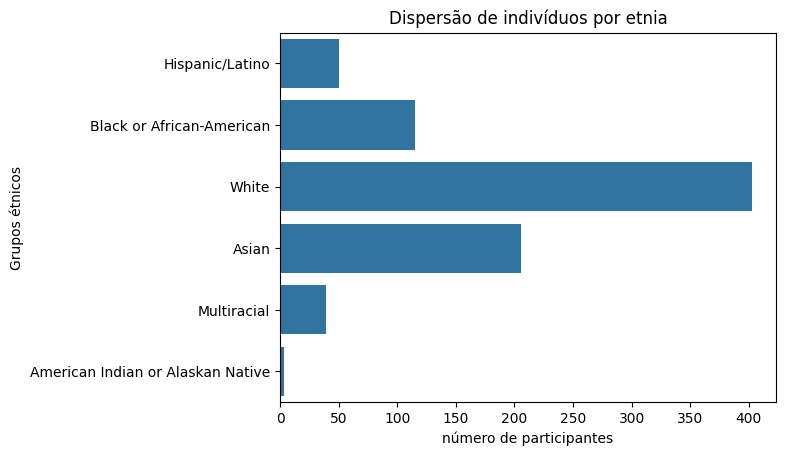

In [18]:
etnias_bar = sns.countplot(y = X_treino["Ethnicity"])

etnias_bar.set_xlabel("número de participantes")
etnias_bar.set_ylabel("Grupos étnicos")
etnias_bar.set_title("Dispersão de indivíduos por etnia");

O gráfico revela que o grupo estudado apresenta diversas etinias distintas, tendo como grupo majoritário os indivíduos brancos, equivalentes a quase metade do grupo. 

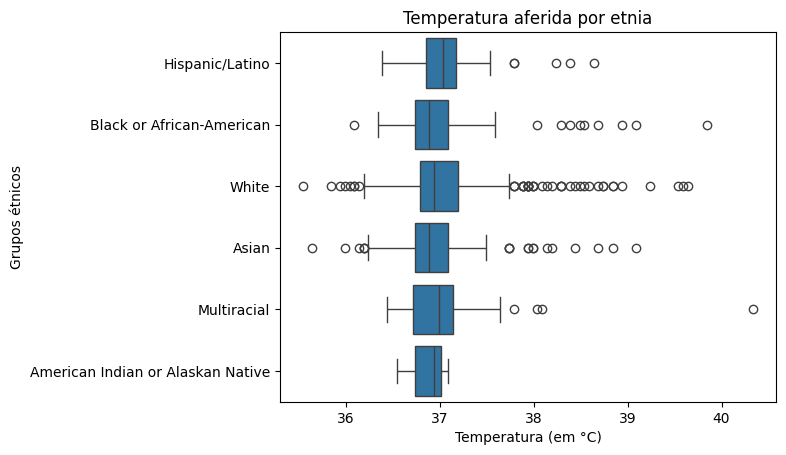

In [19]:
box = sns.boxplot(y = X_treino["Ethnicity"],x = y_treino)

box.set_xlabel("Temperatura (em °C)")
box.set_ylabel("Grupos étnicos")
box.set_title("Temperatura aferida por etnia");

Paralelamente ao gráfico observado anteriormente, este revela a mediana da temperatura para cada grupo étnico e a dispersão da parte central desses dados. Como era de se esperar, a etnia não gera grandes influências na variação da temperatura corporal, além disso, os grupos `White` e `Asian` apresentam mais outliers que os outros grupos devido à maior quantidade de indivíduos pertencentes a eles, garantindo mais informações e mais precisão.

#### Atributos numéricos 

In [20]:
colunas_numericas = X_treino.select_dtypes(include=['int64', 'float64']).columns

X_treino[colunas_numericas].describe().T

,count,mean,std,min,25%,50%,75%,max
T_atm,816.0,24.122304,1.358118,20.2000,23.400000,24.000000,24.700000,29.1000
Humidity,816.0,29.034069,13.276496,9.9000,17.600000,26.600000,36.900000,61.2000
Distance,814.0,0.747076,2.746941,0.5400,0.600000,0.610000,0.700000,79.0000
T_offset1,816.0,0.967986,0.355694,-0.2175,0.772500,0.945000,1.142500,2.7150
Max1R13_1,816.0,35.604195,0.573977,33.9175,35.250000,35.552500,35.865625,38.4050
Max1L13_1,816.0,35.612670,0.557875,34.1225,35.269375,35.563750,35.890000,38.0425
aveAllR13_1,816.0,34.899167,0.719713,31.7700,34.459167,34.917083,35.305000,37.5750
aveAllL13_1,816.0,35.013513,0.648060,32.9025,34.627500,34.997500,35.378750,37.6800
T_RC1,816.0,35.666477,0.556575,33.9850,35.334375,35.602500,35.910625,38.3850
T_RC_Dry1,816.0,35.594269,0.569995,33.8250,35.256250,35.537500,35.853125,38.3800


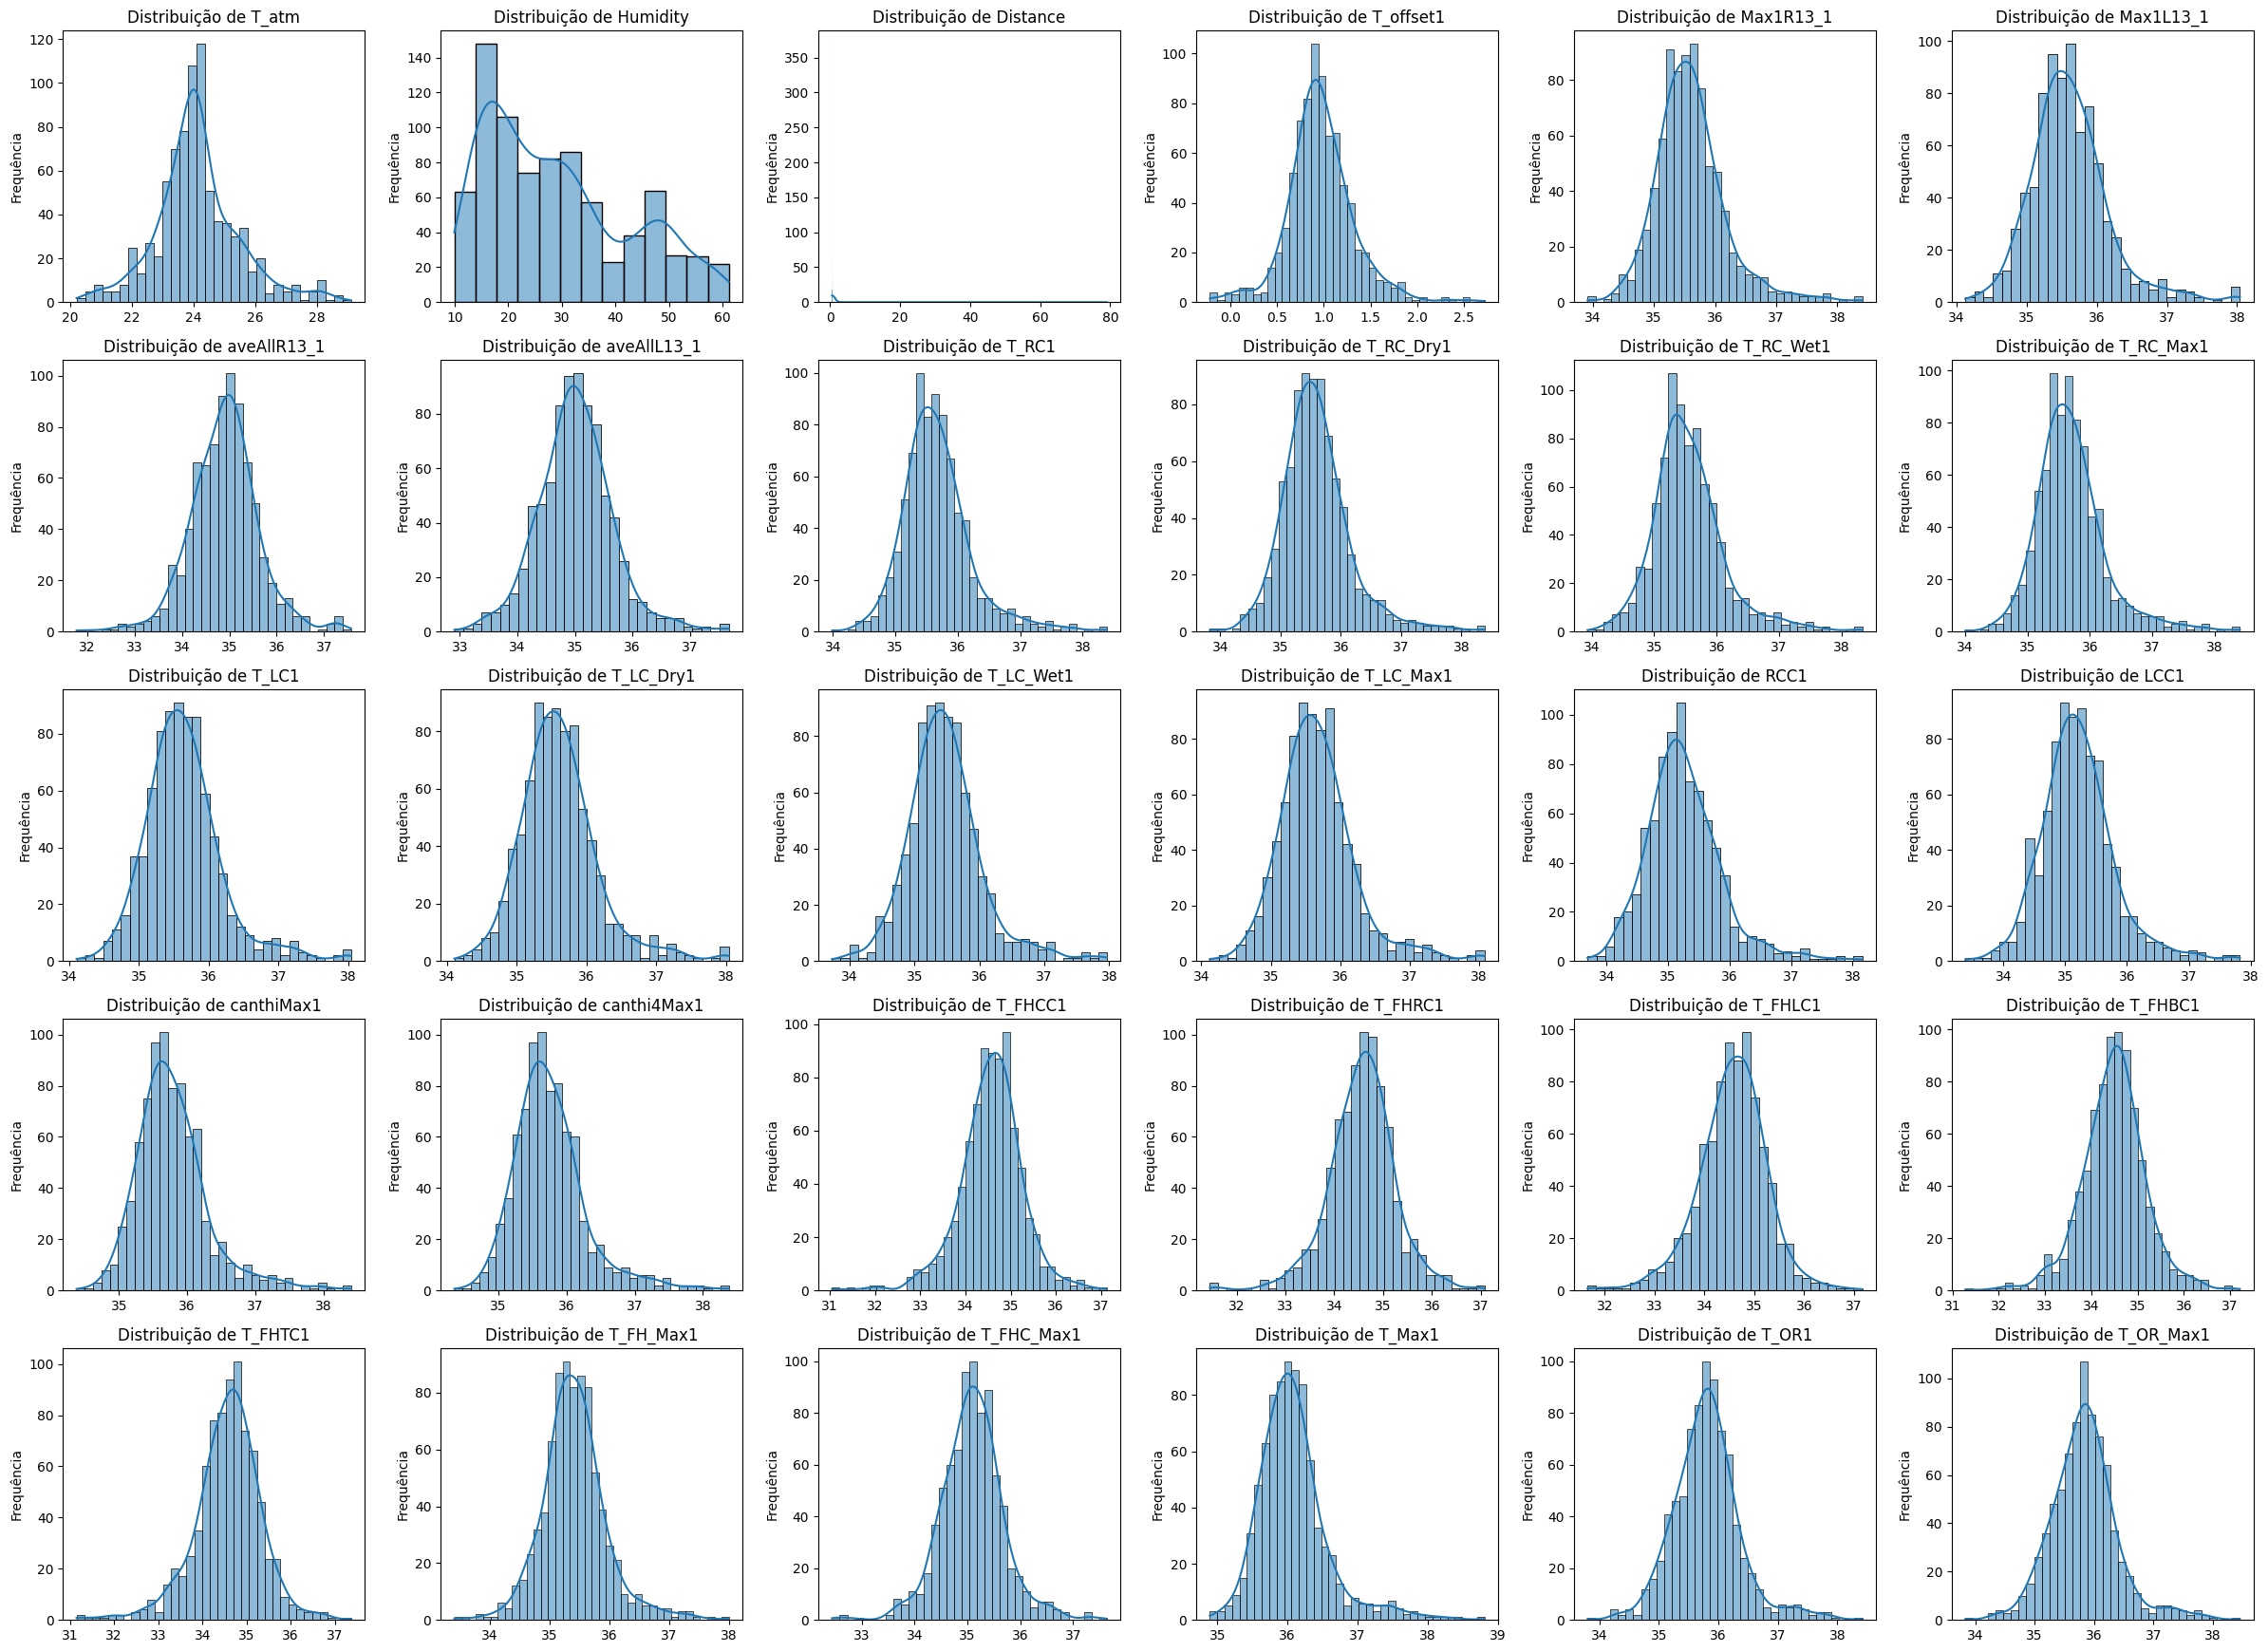

In [21]:
n_colunas = 6
n_linhas = math.ceil(len(colunas_numericas) / n_colunas)

plt.figure(figsize=(n_colunas * 4, n_linhas * 3.5))

for i, coluna in enumerate(colunas_numericas):
    plt.subplot(n_linhas, n_colunas, i + 1)
    sns.histplot(data=X_treino, x=coluna, kde=True)
    plt.title(f"Distribuição de {coluna}")
    plt.xlabel("")
    plt.ylabel("Frequência")


plt.tight_layout()
plt.show()

Acima, cada gráfico revela a correlação entre um atributo numérico e a frequência em que ele é medido, permitindo uma visão geral dos dados. Todavia, o gráfico de distância destoa dos outros por apresentar valores muito pequenos. Por esse motivo, ele será abordado de forma mais aprofundada a seguir. 

In [22]:
X_treino["Distance"].describe()

count    814.000000
mean       0.747076
std        2.746941
min        0.540000
25%        0.600000
50%        0.610000
75%        0.700000
max       79.000000
Name: Distance, dtype: float64

O dado `Distance` informa a distância entre o voluntário e a câmera térmica. Por ser medido em metros, o valor 79 informado pelo `max`não condiz com o que seria adequado para aferir uma temperatura bucal, o que indica que os dados apresentam valores com erros, possivelmente de digitação. Por esse motivo, é fundamental observar os valores para aferir se há mais erros e dados ausentes.

In [23]:
X_treino["Distance"].sort_values(ascending = False)

97     79.00
112     0.92
72      0.90
200     0.85
115     0.84
       ...  
666     0.54
735     0.54
568     0.54
903      NaN
902      NaN
Name: Distance, Length: 816, dtype: float64

Isso revela que apenas o 79 desvia da faixa, seguindo a teoria de erro de digitação e que há dois valores inexistentes.

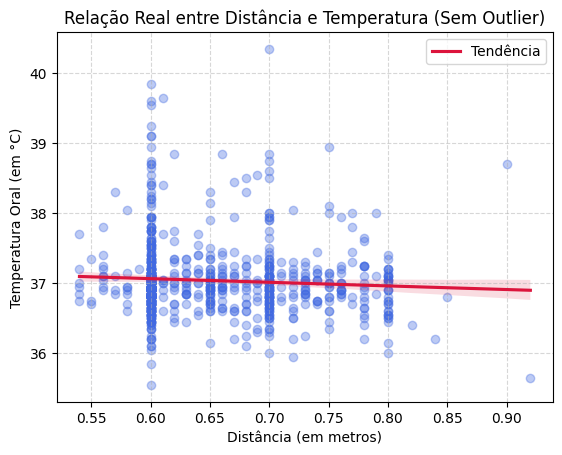

In [24]:
dist_corrigida = X_treino["Distance"] < 2
dist_limpa = X_treino.loc[dist_corrigida, "Distance"]
temp_limpa = y_treino[dist_corrigida]

plt.figure
sns.regplot(
    x=dist_limpa,
    y=temp_limpa,
    scatter_kws={"alpha": 0.35, "color": "royalblue"},
    line_kws={"color": "crimson", "label": "Tendência"},
)

plt.xlabel("Distância (em metros)")
plt.ylabel("Temperatura Oral (em °C)")
plt.title("Relação Real entre Distância e Temperatura (Sem Outlier)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

Para a montagem do código, o atributo `Distance` foi filtrado para valores menores que dois. Essa decisão foi tomada pois, como discutido acima, valores altos possuem altas chances de serem consequência de erros ao registrar, então foi decidido retirar, já que se trata de apenas um número, o 79.

Como é possível observar pelo gráfico acima, o aumento da distância entre a câmera e os indivíduos equivale a uma redução da temperatura medida. Isso é comprovado por `Tendência`, que apresenta uma inclinação negativa, mostrando que quanto maior a distância menos precisa é a temperatura aferida, resultado em números menores.

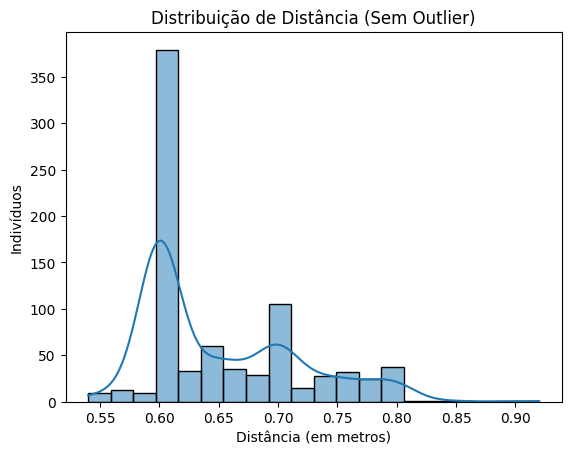

In [25]:
plt.figure
sns.histplot(X_treino[dist_corrigida]["Distance"], bins=20, kde=True)
plt.title("Distribuição de Distância (Sem Outlier)")
plt.xlabel("Distância (em metros)")
plt.ylabel("Indivíduos")
plt.show()


O histograma mostra que a grande maioria dos indivíduos teve sua temperatura oral aferida a 0,6 metros de distância. Todavia, sabendo que a distância influencia os valores medidos, uma variação grande entre as posições para a medição pode resultar em valores inadequados, influenciando o resultado final.

Outro ponto importante de ser abordado é a correlação entre os dados numéricos. Para isso, a correlação de Spearman será utilizada, apresentando uma tabela de correlação entre eles.

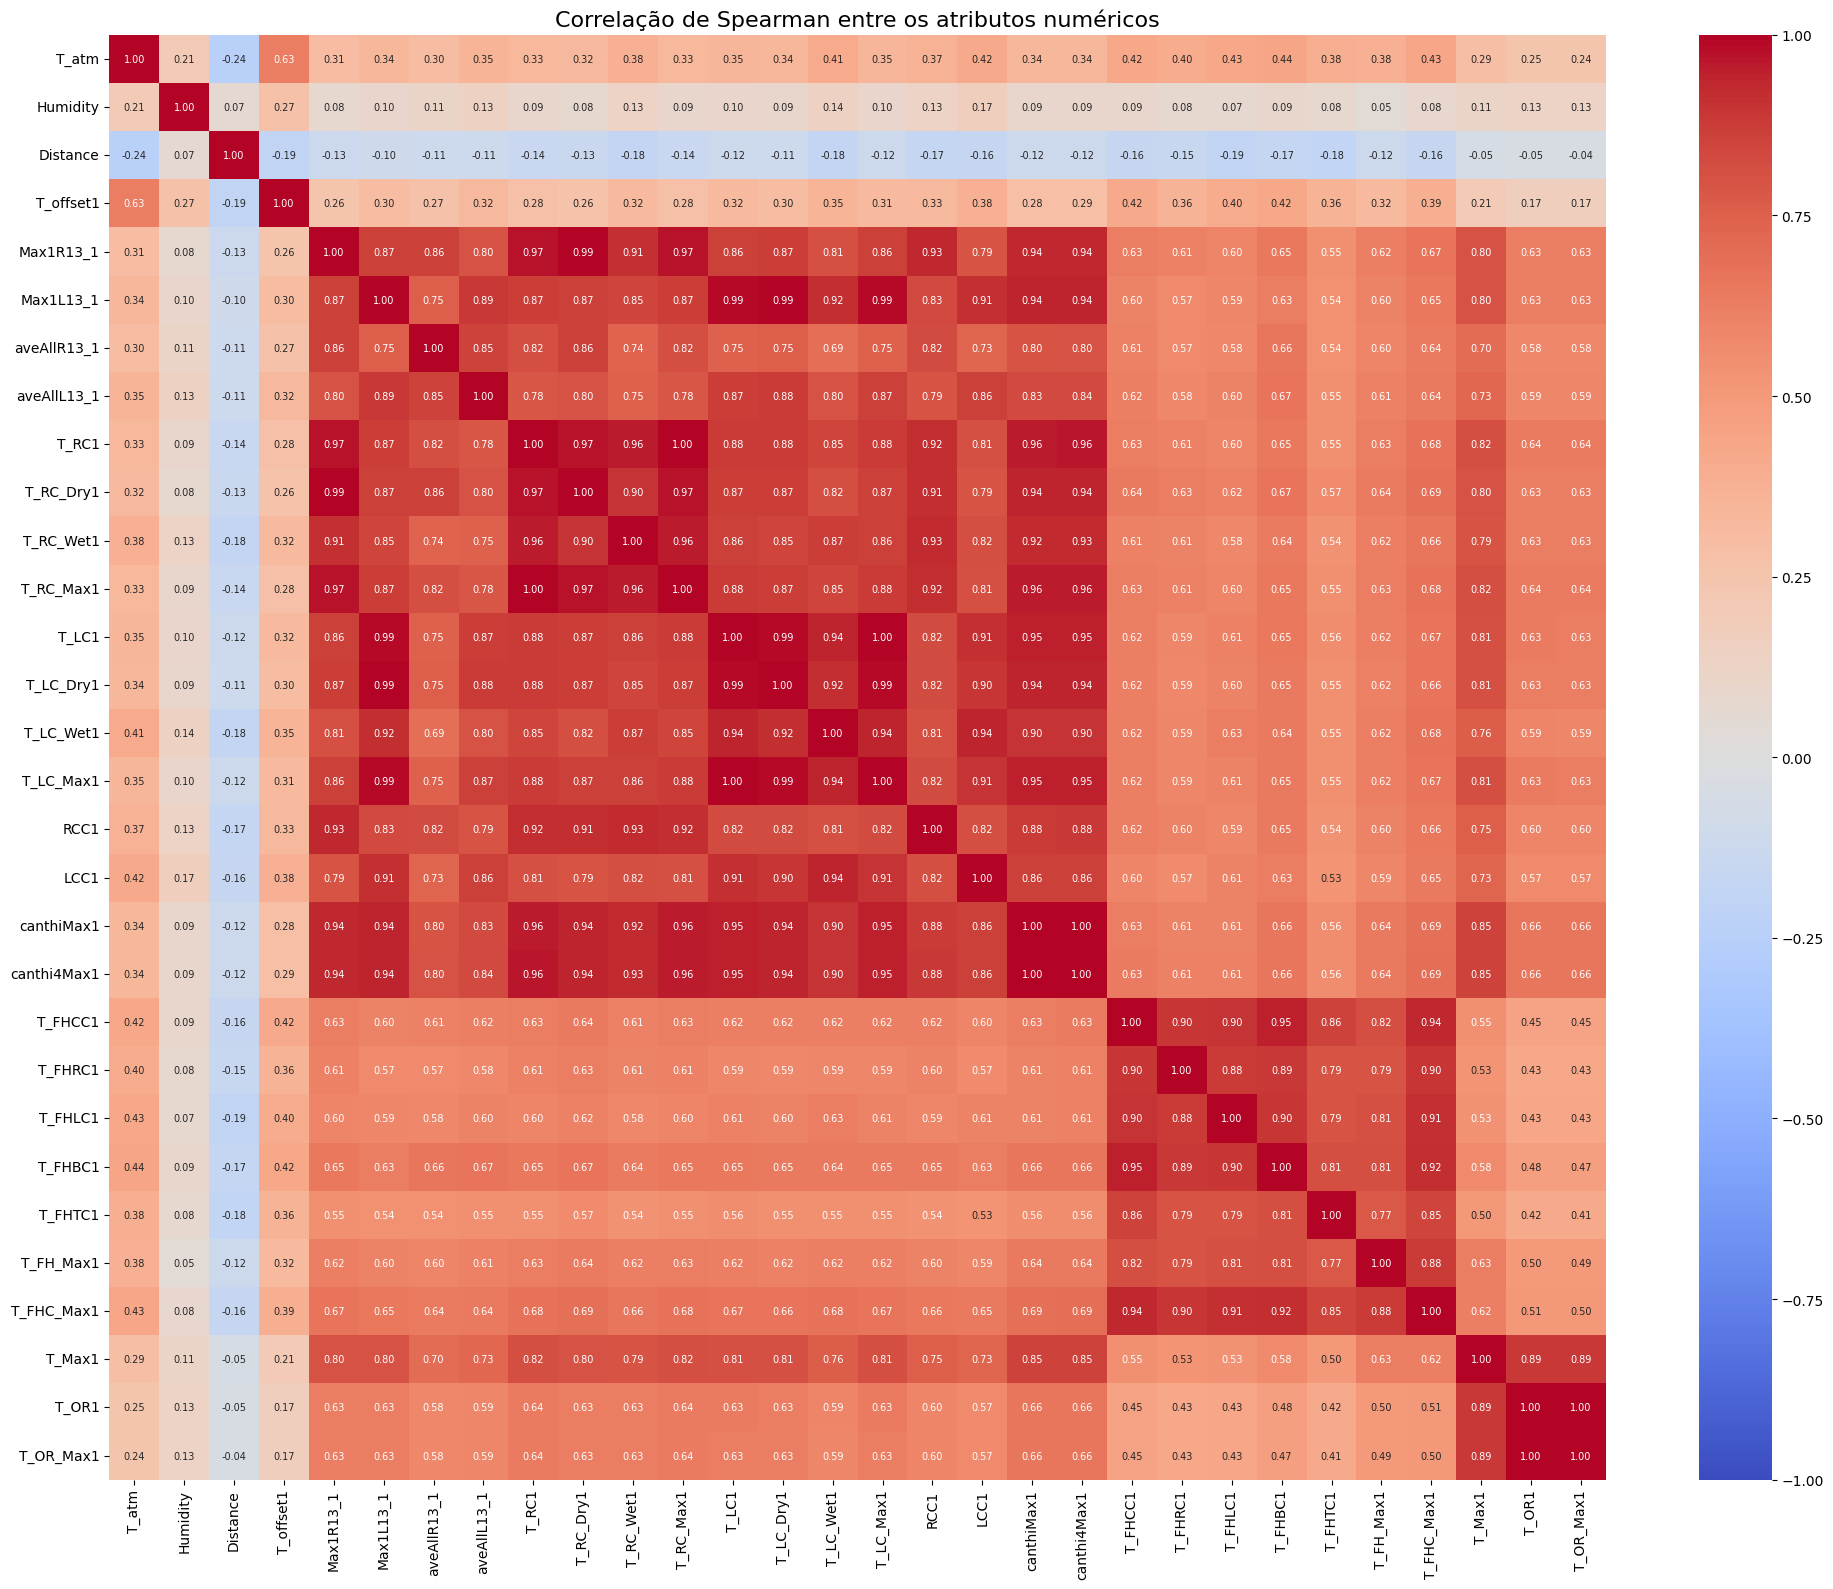

In [26]:
numericas = X_treino.select_dtypes(include="number").columns
corr= X_treino[numericas].corr(method="spearman")

fig, ax = plt.subplots(figsize=(20, 16))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, annot_kws={"size": 7}, ax=ax)

ax.set_title(
    "Correlação de Spearman entre os atributos numéricos", fontsize=16
)
plt.tight_layout()
plt.show()

O gráfico apresenta uma forte correlação entre as variáveis de temperatura, o que pode ser observado pela cor vermelha forte, que representa uma forte correlação positiva. Já as variáveis ambientais, como `Distance` e `Humidity` apresentam baixa correlação com as outras, o que é revelado pelas cores quase neutras e frias que representam correlação negativa.

## Pré-processamento dos dados

In [27]:
vazios = X_treino.isna().sum()
print(vazios)

Gender         0
Age            0
Ethnicity      0
T_atm          0
Humidity       0
Distance       2
T_offset1      0
Max1R13_1      0
Max1L13_1      0
aveAllR13_1    0
aveAllL13_1    0
T_RC1          0
T_RC_Dry1      0
T_RC_Wet1      0
T_RC_Max1      0
T_LC1          0
T_LC_Dry1      0
T_LC_Wet1      0
T_LC_Max1      0
RCC1           0
LCC1           0
canthiMax1     0
canthi4Max1    0
T_FHCC1        0
T_FHRC1        0
T_FHLC1        0
T_FHBC1        0
T_FHTC1        0
T_FH_Max1      0
T_FHC_Max1     0
T_Max1         0
T_OR1          0
T_OR_Max1      0
dtype: int64


Como é possível observar, apenas o `Distance` apresenta valores ausentes que foram observados anteriormente. Logo, não há necessidade de descartar atributos com dados ausentes. 

Outro ponto importante é decidir como será lidado o "79" no atributo `Distance`. Para isso, será medido o desvio padrão e a média com e sem esse dado para decidir seus impactos e como lidar com ele.

### Distance

In [28]:
desvio_79 = X_treino["Distance"].std()
media_79 = X_treino["Distance"].mean()

dist_sem = X_treino.loc[X_treino["Distance"]<2, "Distance"] 
desvio_s = dist_sem.std()
media_s = dist_sem.mean()

print(f'Os valores de desvio padrão e média considerando o 79 é {desvio_79} e {media_79}')
print(f'Já os valores de desvio padrão e média sem o 79 são {desvio_s} e {media_s} ')

Os valores de desvio padrão e média considerando o 79 é 2.7469413698949916 e 0.747076167076167
Já os valores de desvio padrão e média sem o 79 são 0.06650445230732778 e 0.6508241082410823 


Como é possível observar, o 79 causa grande alteração no valor do desvio padrão, o que causa muitas alterações nos cálculos. Por esse  motivo, ele não pode ser contabilizado, todavia, os dados desse voluntário não podem ser excluídos completamente pois apenas um valor destoa do padrão, enquanto há outros 32 dados válidos referentes a diferentes medidas. Assim, ele será transformado em um dado vazio e todos os valores vazios serão substituídos pela mediana dos dados de treino o que será aplicado tanto aos dados de treino quanto aos dados de teste, pois é uma necessidade fixa pra ambos, mas que só pode se basear no treino para que não haja vazamento de dados. 

In [29]:
X_treino.loc[X_treino["Distance"]>2, "Distance"] = np.nan
X_teste.loc[X_teste["Distance"]>2, "Distance"] = np.nan

soma = X_treino["Distance"].isna().sum()
print(soma)

3


A soma equivalendo a 3 comprova que o 79 passou a ser um valor vazio. O próximo passo agora é tornar todos os Nan equivalentes à mediana.

### Gender

Como o atributo `Gender` é nesse conjunto de dados categorizado como binário e nominal, o `OneHotEncoder` será utilizado para torná-lo um atributo numérico para sua aplicação no pipeline. Assim, a coluna categórica será substituida por um numérica binária, em que os valores 0 e 1 equivalem a um dos gêneros.

Para fazer isso, são utilizados dois métodos: o `fit` que é responsável por ajustar os dados de treino a uma "regra" ao mapear as categorias em uma coluna, já o `transform` aplica essa "regra" aplicando os valores, por exemplo aplicando o `female`= 0 e o `male`= 1.

In [30]:
enc_gender = OneHotEncoder(drop = 'if_binary')

g_treino_codif = enc_gender.fit_transform(X_treino[["Gender"]])
enc_gender.categories_

[array(['Female', 'Male'], dtype=object)]

O `categories_` permite identificar que o `Female` equivale a zero enquando o `Male` a um. 

Para o treino, `fit_transform` é utilizado aplicando ambos; já para o teste, como a regra já está definida, apenas `transform` será aplicado, impedindo que ocorra uma inconsistência entre as regras ou vazamento de dados.

In [31]:
g_teste_codif = enc_gender.transform(X_teste[["Gender"]])

print(g_treino_codif.shape)
print(g_teste_codif.shape)

(816, 1)
(204, 1)


### Ethnicity

Assim como `Gender`, o `Ethnicity` também é um dado categórico e é necessário torná-lo numérico. Uma diferença entre eles é que esse atributo apresenta diversos grupos, então a aplicação do `if_binary` deixa de ser aplicado. Além disso, uma informação importante é que os dados treino apresentaram até o momento apenas 6 grupos étnicos, todavia o material acerca desse banco de dados indica que há um total de sete grupos. Isso indica que provavelmente eles estão no grupo teste mas não no treino ou que não está presente entre os 1020 voluntários.

In [32]:
enc_ethnic = OneHotEncoder()

e_treino_codif = enc_ethnic.fit_transform(X_treino[["Ethnicity"]])
e_teste_codif = enc_ethnic.transform(X_teste[["Ethnicity"]])

print(e_treino_codif.shape)
print(e_teste_codif.shape)

(816, 6)
(204, 6)


Como essa etnia não apareceu nem nos dados de teste, ela não está presente entre os voluntários, assim para o caso em que esteja presente, o `handle_unkown = "ignore"` será aplicado no encoder dentro do Pipeline. Isso se dá pois, se o programa acusar erro no Optuna, ele será parado, o que pode quebrar o Pipeline.

### Age

Para lidar com o atributo age, que lida com faixas etárias, a primeira etapa é vizualizar os dados que estão sendo lidados. Nesse caso, se tratam de 8 grupos distintos, variando de 18 a mais de 60 anos. 

In [33]:
count_age = X_treino["Age"].value_counts()
count_age

Age
18-20    426
21-25    286
26-30     54
31-40     23
51-60      9
21-30      9
41-50      6
>60        3
Name: count, dtype: int64

Os grupos etários serão representados por números em ordem ascendente, assim `18-20` passa a ser equivalente a 0; `21-25`, `26-30` e `21-30` equivalem a 1, `31-40` a 2 e assim respectivamente. Outro ponto é que com esse agrupamento de certos grupos, é adequado verificar a quantidade de volutários em cada um desses novos grupos, para organizar isso, a função `map` é utilizada pois "[...] permite aplicar uma função a todos os itens de uma sequência (como uma lista) e retornar uma nova sequência com os resultados. Em outras palavras, ela 'mapeia' cada valor da sequência original para um novo valor, de acordo com a função fornecida." [5]. 

In [34]:
map_age = {
    "18-20": 0,
    "21-25": 1,
    "26-30": 1,
    "21-30": 1,
    "31-40": 2,
    "41-50": 3,
    "51-60": 4,
    ">60": 5,
}

X_treino["Age_num"] = X_treino["Age"].map(map_age)
X_teste["Age_num"] = X_teste["Age"].map(map_age)

In [35]:
X_treino["Age_num"].value_counts()

Age_num
0    426
1    349
2     23
4      9
3      6
5      3
Name: count, dtype: int64

Como esperado, a soma total dos valores de `Age_num` indica que a criação da nova coluna equivalente à `Age` original, mas dessa vez com os valores dos grupos substituídos como discutido anteriormente.

## Preparação do Pipeline

"O `Pipeline` atua como uma tubulação de informação: a informação que entra no `Pipeline` é transmitida para todas as componentes do `Pipeline` até o fim." [notebook7.0] seu uso é essencial por evitar o vazamento de dados pelo pré-processamento.
Para realizar isso, são definidas as colunas que sofrerão alterações ao longo do `Pipeline`, sendo elas uma para cada atributo categórico definidos anteriormente e uma unindo todos atributos numéricos incluindo o `Age` corrigido (`Age_num`).

In [36]:
col_gender = ["Gender"]
col_dist = ["Distance"]
col_ethnic = ["Ethnicity"]

col_num = [
    "Age_num",
    "T_atm",
    "Humidity",
    'T_offset1',
    'Max1R13_1',
    'Max1L13_1',
    'aveAllR13_1',
    'aveAllL13_1',
    'T_RC1',
    'T_RC_Dry1',
    'T_RC_Wet1',
    'T_RC_Max1',
    'T_LC1',
    'T_LC_Dry1',
    'T_LC_Wet1',
    'T_LC_Max1',
    'RCC1',
    'LCC1',
    'canthiMax1',
    'canthi4Max1',
    'T_FHCC1',
    'T_FHRC1',   
    'T_FHLC1',
    'T_FHBC1',
    'T_FHTC1',
    'T_FH_Max1', 
    'T_FHC_Max1',
    'T_Max1',
    'T_OR1',
    'T_OR_Max1',
]

Como discutido anteriormente, as estratégias para lidar com os dados serão aplicadas agora para serem válidas ao longo de toda sua aplicação no optuna. Além do que foi falado anteriormente, será aplicado o `StandardScaler` sobre os dados numéricos a fim de evitar que eles sofram grandes variações e para que todos se encontrem em uma mesma métrica, sendo valores entre 0 e 1. 

Assim, `Distance`, após transformar o 79 em um valor vazio, torna todos os Nan equivalentes à mediana; `Gender` faz uma coluna só com zero equivalente a `Female` e um a `Male`; por fim, `Ethnicity` irá ignorar caso apareça algum grupo raro de etnia.

In [37]:
preprocess = make_column_transformer(
    (make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), col_dist),
    (OneHotEncoder(drop='if_binary'), col_gender),
    (OneHotEncoder(handle_unknown='ignore'), col_ethnic),
    (StandardScaler(), col_num)
    )

In [38]:
X_treino_prep = preprocess.fit_transform(X_treino)
print(X_treino_prep.shape)

(816, 38)


Como esperado, o número de atributos passou de 33 para 38. Isso se explica pela soma de 1 `Distance`, 1 `Gender`, 6 `Ethnicity` e outros 30 numéricos (sabendo que `Distance` foi retirado dessa lista por precisar de um tratamento próprio consequente do 79 e dos Nan).

## Validação cruzada e baseline

O baseline é essencial para permitir observar a efetividade dos modelos aplicados, já a validação cruzada permite a aleatoriedade nos treinos. Para realizar isso, o `KFold` define a divisão dos voluntários (nesse caso serão 5 grupos); o `cross_val_score` realiza 5 rodadas e devolve 5 notas,  um por parte das dividades anteriormente; `scoring = neg_root_mean_squared_error` é utilizado porque essa nota é o RMSE com o sinal negativo, assim o `rmse_scores` age para voltar esse valor ao normal.

In [39]:
cv = KFold(n_splits=5, shuffle=True, random_state=1020)
pipe_baseline = make_pipeline(preprocess, DummyRegressor(strategy = "mean"))

notas_neg = cross_val_score(
    pipe_baseline, 
    X_treino, 
    y_treino, 
    cv = cv, 
    scoring ="neg_root_mean_squared_error"
)
rmse_notas = - notas_neg

print(f"RMSE médio: {rmse_notas.mean():.4f} °C")
print(f"Desvio padrão do RMSE: {rmse_notas.std():.4f} °C")

RMSE médio: 0.5221 °C
Desvio padrão do RMSE: 0.0534 °C


In [40]:
y_treino.describe()

count    816.000000
mean      37.032341
std        0.524772
min       35.540000
25%       36.740000
50%       36.940000
75%       37.140000
max       40.340000
Name: aveOralM, dtype: float64

Para conferir o desvio padrão, foi realizado o `describe()` sobre o `y_treino`, validando o resultado do baseline. Como o `DummyRegressor` aplicado sempre prevê a média das temperaturas para todos os voluntários, o erro médio quadrático (RMSE) das suas previsões é muito próximo ao desvio padrão da própria amostra.Assim, como os valores do desvio padrão de ambos é semelhante, sabe-se que o baseline se comporta como previsto.

## Modelos

Os modelos escolhidos para aplicar o `pipeline` foram: Ridge, k-NN, Árvore de decisão, Floresta aleatória e Gradiente boosting. Os modelos k-NN, Árvore de decisão e Floresta aleatória foram escolhidos por já serem conhecidos e apresentados no curso pelo material didático disponibilizado pelo professor Daniel R. Cassar. Todavia, o `Ridge` foi aplicado no lugar do `LinearRegression` que foi apresentado no material de aula, pois esse conjunto de dados apresenta em seu dataset cerca de 30 medições de temperatura similares, o que seria difícil para o `LinearRegression` lidar, enquanto o `Ridge` é uma regressão linear com regularização, o que evita *overfitting* e estabiliza a previsão [7]. Já o *Gradiente Boosting* foi decidido como quinto modelo pois difere ao construir várias árvores de decisão em sequência, sendo que cada uma corrige os erros das anteriores, conseguindo capturar relações não lineares complexas entre as temperaturas do rosto e a temperatura oral.

In [41]:
modelos = {
    "Ridge": Ridge(random_state=1020),
    "k-NN": KNeighborsRegressor(),
    "Árvore de Decisão": DecisionTreeRegressor(random_state=1020),
    "Floresta Aleatória": RandomForestRegressor(random_state=1020),
    "Gradient Boosting": GradientBoostingRegressor(random_state=1020)
}

for nome, modelo in modelos.items():
    pipelines = make_pipeline(preprocess, modelo)
    notas_neg = cross_val_score(
        pipelines,
        X_treino, 
        y_treino, 
        cv = cv, 
        scoring ="neg_root_mean_squared_error"
)
    rmse_notas = - notas_neg

    print(f"RMSE médio com {nome}: {rmse_notas.mean():.4f} °C")
    print(f"Desvio padrão do RMSE: {rmse_notas.std():.4f} °C")

RMSE médio com Ridge: 0.2615 °C
Desvio padrão do RMSE: 0.0053 °C
RMSE médio com k-NN: 0.2883 °C
Desvio padrão do RMSE: 0.0084 °C
RMSE médio com Árvore de Decisão: 0.3636 °C
Desvio padrão do RMSE: 0.0211 °C
RMSE médio com Floresta Aleatória: 0.2615 °C
Desvio padrão do RMSE: 0.0126 °C
RMSE médio com Gradient Boosting: 0.2622 °C
Desvio padrão do RMSE: 0.0124 °C


Os resultados revelam que em todos os modelos o RMSE médio ficou bem abaixo do baseline (0.5221 °C). Dentre eles, o que apresentaram maior redução foram o Ridge e a Floresta Aleatória (0.2615°C), que se diferenciam pelo valor do desvio padrão do RMSE, que enquanto no Ridge equivale à apenas 0.0053 °C, na Floresta aleatória o valor aumenta para 0.0126°C. Além disso, o Gradiente Boosting também apresentou um valor muito próximo dos dois modelos apresentados anteriormente, diferindo apenas por apenas sete décimos de milésimos (0.2622 °C). Por outro lado, também é possível observar que o modelo que apresentou menor redução no RMSE médio foi a Árvore de decisão, apresentando como resultado 0.3636°C.

Esse "empate" entre Ridge, Floresta Aleatória e Gradiente Boosting indica que a relação entre os dados de temperatura de outras partes do rosto (que predominam entre os valores menores como dito anteriormente) e a temperatura oral (`aveOralM`) é principalmente porporcional, como foi indicado pelo mapa de correlação visto na análise de dados. Isso se explica, pelo fato de que se essa relação não fosse linear os modelos baseados em árvores teriam se saído muito melhor que Ridge e não haveria toda essa proximidade.

## Optuna

O Optuna é um framework de software para otimização automática de hiperparâmetros, projetado especificamente para aprendizado de máquina [8]. O primeiro passo para sua implementação é criar um estudo para cada algoritmo utilizando o `case_study`, isso é necessário pois cada modelo apresenta hiperparâmetros próprios e misturá-los fará com que o Optuna escolhesse os hiperparâmetros resultando em alguns algoritmos com menos de 100 combinações eles, o que destoa do pré-estabelecido pelo material guia.

O `case_study` será aplicado seguindo a seguinte ordem: Ridge, k-NN, Árvore de Decisão, Floresta Aleatória e Gradiente Boosting. Assim, os primeiros que rodam mais rápido permitem validar o código do Optuna antes que ele seja aplicado em comits de árvores, que são mais pesados.

No Ridge, o principal hiperparâmetro é o `alpha`. Ele controla a intensidade da penalidade aplicada aos coeficientes do modelo para reduzir o *overfitting* e lidar com multicolinearidade. Como esse hiperparâmetro aceita valores decimais, será utilizado o `trial.suggest_float()`; para usar o `alpha` é necessário estabelecer uma faixa de grandeza, já que seu efeito só muda de verdade quando é multiplicado ou dividido por 10, como não se sabe qual ordem de grandeza é mais adequado, a faixa decidida foi entre $\frac{1}{10^3}$ e $10^3$.

In [61]:
def ridge_int(trial):
    alpha = trial.suggest_float("alpha", 1e-3, 1e3, log = True)

    return make_pipeline(preprocess, Ridge(alpha=alpha, random_state=1020))

Assim como no Ridge, as outras funções passarão pelo mesmo processo, sendo ajustadas para seus respectivos hiperparâmetros. Os valores desses hiperparâmetros foram, em parte, definidos com base nos utilizados em sala de aula e a outra parte foi baseada nos valores padrões presentes em suas respectivas documentações.


In [43]:
def knn_int(trial):
    parametros = {
        "n_neighbors": trial.suggest_int("num_vizinhos", 1, 49, step=4),
        "weights": trial.suggest_categorical("pesos", ["uniform", "distance"]),
        "p": trial.suggest_float("potencia_minkowski", 1, 2),
        "n_jobs": -1,
    }
    
    modelo = make_pipeline(
        preprocess,
        KNeighborsRegressor(**parametros),
    )

    return modelo

In [44]:
def arvore_int(trial):
    params = {
        "max_depth": trial.suggest_int("max_depth", 2, 20),
        "min_samples_split": trial.suggest_int("min_samples_split", 2, 20),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 20),
        "random_state": 1020,
    }
    
    return make_pipeline(preprocess, DecisionTreeRegressor(**params))

In [45]:
def floresta_int(trial):
    parametros = {
        "n_estimators": trial.suggest_int("num_arvores", 5, 300, log=True),
        "min_samples_split": trial.suggest_int("min_exemplos_split", 2, 20),
        "min_samples_leaf": trial.suggest_int("min_exemplos_folha", 1, 20),
        "max_features": trial.suggest_float("num_max_atributos", 0.1, 1),
        
        "n_jobs": -1,
        "bootstrap": True,
        "random_state": 1020,
    }

    modelo = RandomForestRegressor(**parametros)

    return make_pipeline(preprocess, modelo)

In [46]:
def gb_int(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 50, 300, log=True),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "max_depth": trial.suggest_int("max_depth", 1, 8),
        "min_samples_split": trial.suggest_int("min_samples_split", 2, 20),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 20),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "random_state": 1020,
    }
    
    return make_pipeline(preprocess, GradientBoostingRegressor(**params))

Tendo isso feito, agora é hora da função objetivo geral. Ela recebe um conjunto de hiperparâmetros sugeridos pelo Optuna, treina e avalia o modelo com eles, e retorna um único número dizendo o quão boa ou ruim foi aquela tentativa [9] Para isso, as cinco funções anteriores serão unidas em um dicionário contendo o nome do modelo, a função e o número de trials que serão realizados inicialmente para o treino.

In [47]:
estudos = [
    ("Ridge", ridge_int, 250),
    ("k-NN", knn_int, 250),
    ("Árvore de decisão", arvore_int, 250),
    ("Floresta aleatória", floresta_int, 150),
    ("Gradiente boosting", gb_int, 150)
    
]

resultados = {
    
}

In [48]:
def funcao_objetivo(trial, cria_modelo, X, y, cv):
    modelo = cria_modelo(trial)
    scores = cross_val_score(
        modelo,
        X,
        y,
        cv=cv,
        scoring="neg_root_mean_squared_error",
    )
    return -scores.mean()

Para otimizar os hiperparâmetros se utiliza o `create_study`, ele é composto por `direction` que condiz com o problema no caso, é igualado a `minimize`, visto que o objetivo é minimizar o RMSE médio 

In [49]:
for nome, modelo, n_trials in estudos:
    funcao_objetivo_parcial = partial(
        funcao_objetivo,
        cria_modelo = modelo,
        X = X_treino, 
        y = y_treino, 
        cv = cv,
    )

    objeto_estudo = optuna.create_study(
        direction = "minimize", 
        study_name = f'{nome}_final',
        storage= f'sqlite:///optuna_{nome}.db',
        load_if_exists = True
    )
    objeto_estudo.optimize(funcao_objetivo_parcial, n_trials=n_trials)
    resultados[nome] = objeto_estudo

In [50]:
for nome, estudo in resultados.items():
    df_trials = estudo.trials_dataframe()
    tempo_trials = df_trials["duration"].sum()
    print(f'O tempo para {nome} rodar é de {tempo_trials}')

O tempo para Ridge rodar é de 0 days 00:01:21.188267
O tempo para k-NN rodar é de 0 days 00:03:09.397725
O tempo para Árvore de decisão rodar é de 0 days 00:01:45.609935
O tempo para Floresta aleatória rodar é de 0 days 00:10:01.100826
O tempo para Gradiente boosting rodar é de 0 days 00:19:34.849797


In [51]:
for nome, estudo in resultados.items():
    print(f'{nome} apresentou como melhor RMSE médio {estudo.best_value:.4f}, com parâmetros {estudo.best_params}' )

Ridge apresentou como melhor RMSE médio 0.2610, com parâmetros {'alpha': 6.165995677141556}
k-NN apresentou como melhor RMSE médio 0.2772, com parâmetros {'num_vizinhos': 9, 'pesos': 'distance', 'potencia_minkowski': 1.5488732915406414}
Árvore de decisão apresentou como melhor RMSE médio 0.2711, com parâmetros {'max_depth': 3, 'min_samples_split': 2, 'min_samples_leaf': 8}
Floresta aleatória apresentou como melhor RMSE médio 0.2558, com parâmetros {'num_arvores': 247, 'min_exemplos_split': 5, 'min_exemplos_folha': 4, 'num_max_atributos': 0.891943228397204}
Gradiente boosting apresentou como melhor RMSE médio 0.2486, com parâmetros {'n_estimators': 196, 'learning_rate': 0.19329857715286033, 'max_depth': 1, 'min_samples_split': 5, 'min_samples_leaf': 3, 'subsample': 0.804651299773851}


## Resultados do Optuna

A fim de observar os resultados e identificar qual o melhor modelo com base nos valores obtidos pelo Optuna, será criada uma tabela relacionando o modelo, o seu RMSE médio com o Optuna, o desvio padrão do RMSE com o Optuna, valor do pipeline vencedor e a diferença entre ele e a média. 

In [52]:
notas_optuna = {}   
modelos_vencedores = {}
resumo_optuna = []

for nome, fn_montar, n_trials in estudos:
    estudo = resultados[nome]
    pipe_vencedor = fn_montar(estudo.best_trial)
    
    scores = -cross_val_score(
        pipe_vencedor,
        X_treino,
        y_treino,
        cv=cv,
        scoring="neg_root_mean_squared_error",
        n_jobs=-1
    )
    
    notas_optuna[nome] = scores
    modelos_vencedores[nome] = pipe_vencedor
    
    resumo_optuna.append({
        "Modelo": nome,
        "RMSE_Optuna_Mean": scores.mean(),
        "RMSE_Optuna_Std": scores.std(ddof=1),
        "Best_Value_Optuna": estudo.best_value,
        "Diff_Best_Value": abs(scores.mean() - estudo.best_value)
    })

df_optuna = pd.DataFrame(resumo_optuna)
display(df_optuna)

,Modelo,RMSE_Optuna_Mean,RMSE_Optuna_Std,Best_Value_Optuna,Diff_Best_Value
0,Ridge,0.261037,0.005616,0.261037,0.000000e+00
1,k-NN,0.277239,0.011594,0.277239,0.000000e+00
2,Árvore de decisão,0.271122,0.003682,0.271122,0.000000e+00
3,Floresta aleatória,0.255802,0.010874,0.255802,1.110223e-16
4,Gradiente boosting,0.248645,0.010534,0.248645,0.000000e+00


Todos os modelos apresentaram redução em comparação com o baseline que originalmente apresentou RMSE médio de 0,5221 °C, em especial o Gradiente boosting (0,2483 ± 0,0104 °C) e a Floresta aleatória (0,2545 ± 0,0084 °C), que cortaram o erro médio pela metade. O Ridge também se destacou com desempenho competitivo e baixa variabilidade entre os folds (0,2610 ± 0,0056 °C), enquanto Árvore de decisão (0,2711 ± 0,0037 °C) e k-NN (0,2772 ± 0,0116 °C) tiveram erros ligeiramente maiores,mas ainda bem abaixo da referência inicial.

In [53]:
mapa_nomes = {
    "Árvore de Decisão": "Árvore de decisão",
    "Floresta Aleatória": "Floresta aleatória",
    "Gradient Boosting": "Gradiente boosting",
}

notas_padrao = {}
resumo_padrao = []

for nome_raw, modelo_padrao in modelos.items():
  nome = mapa_nomes.get(nome_raw, nome_raw)

  pipe_padrao = make_pipeline(preprocess, modelo_padrao)

  scores_p = -cross_val_score(
      pipe_padrao,
      X_treino,
      y_treino,
      cv=cv,
      scoring="neg_root_mean_squared_error",
      n_jobs=-1,
  )

  notas_padrao[nome] = scores_p
  resumo_padrao.append({
      "Modelo": nome,
      "RMSE_Padrao_Mean": scores_p.mean(),
      "RMSE_Padrao_Std": scores_p.std(ddof=1),
  })

df_padrao = pd.DataFrame(resumo_padrao)
display(df_padrao)

,Modelo,RMSE_Padrao_Mean,RMSE_Padrao_Std
0,Ridge,0.261518,0.005870
1,k-NN,0.288296,0.009356
2,Árvore de decisão,0.363618,0.023638
3,Floresta aleatória,0.261501,0.014080
4,Gradiente boosting,0.262156,0.013860


In [54]:
tabela_final = pd.merge(df_padrao, df_optuna, on="Modelo", how="outer")

linha_baseline = pd.DataFrame([{
    "Modelo": "Baseline",
    "RMSE_Padrao_Mean": 0.5221,
    "RMSE_Padrao_Std": 0.0534,
    "RMSE_Optuna_Mean": np.nan,
    "RMSE_Optuna_Std": np.nan,
}])

tabela_final = pd.concat([tabela_final, linha_baseline], ignore_index=True)

tabela_final = tabela_final.sort_values(
    by="RMSE_Optuna_Mean",
    ascending=True,
    na_position="last"
).reset_index(drop=True)

colunas = [
    "Modelo",
    "RMSE_Padrao_Mean",
    "RMSE_Padrao_Std",
    "RMSE_Optuna_Mean",
    "RMSE_Optuna_Std",
]
tabela_final = tabela_final[colunas]

formatacao = {
    col: (lambda x: "" if pd.isna(x) else f"{x:.4f}")
    for col in colunas if col != "Modelo"
}
display(tabela_final.style.format(formatacao))

,Modelo,RMSE_Padrao_Mean,RMSE_Padrao_Std,RMSE_Optuna_Mean,RMSE_Optuna_Std
0,Gradiente boosting,0.2622,0.0139,0.2486,0.0105
1,Floresta aleatória,0.2615,0.0141,0.2558,0.0109
2,Ridge,0.2615,0.0059,0.2610,0.0056
3,Árvore de decisão,0.3636,0.0236,0.2711,0.0037
4,k-NN,0.2883,0.0094,0.2772,0.0116
5,Baseline,0.5221,0.0534,,


Mesmo com os hiperparâmetros padrão, todos os modelos superaram amplamente o Baseline (0,5221 ± 0,0534), sendo Floresta aleatória (0,2615 ± 0,0141), Ridge (0,2615 ± 0,0059) e Gradiente boosting (0,2622 ± 0,0139) os mais fortes de saída, enquanto a Árvore de decisão isolada teve o pior desempenho padrão (0,3636 ± 0,0236) e maior variabilidade entre os folds.   Com a otimização via Optuna, todos os algoritmos reduziram o RMSE médio: o Gradiente boosting assumiu a liderança (0,2483 ± 0,0104), seguido pela Floresta aleatória (0,2545 ± 0,0084), com ganhos também expressivos para a Árvore de decisão (que caiu de 0,3636 para 0,2711 e reduziu bastante o desvio padrão para 0,0037), k-NN (0,2883 para 0,2772) e Ridge (0,2615 para 0,2610, mantendo a menor dispersão entre os modelos com ajuste).

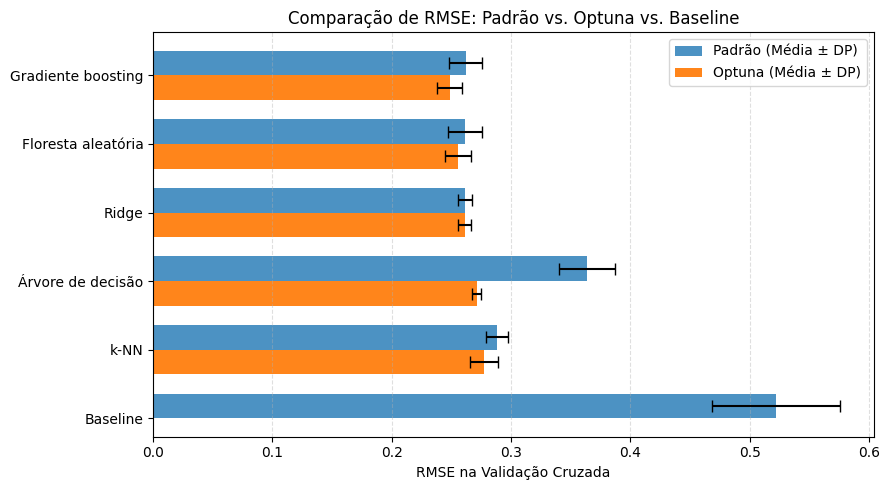

In [55]:
df_plot = tabela_final.sort_values(
    by="RMSE_Optuna_Mean", ascending=True, na_position="last"
).reset_index(drop=True)

y = np.arange(len(df_plot))
altura = 0.36

fig, ax = plt.subplots(figsize=(9, 5))

ax.barh(
    y - altura / 2,
    df_plot["RMSE_Padrao_Mean"],
    height=altura,
    xerr=df_plot["RMSE_Padrao_Std"],
    capsize=4,
    label="Padrão (Média ± DP)",
    alpha=0.8,
)

mascara_opt = df_plot["RMSE_Optuna_Mean"].notna()
ax.barh(
    y[mascara_opt] + altura / 2,
    df_plot.loc[mascara_opt, "RMSE_Optuna_Mean"],
    height=altura,
    xerr=df_plot.loc[mascara_opt, "RMSE_Optuna_Std"],
    capsize=4,
    label="Optuna (Média ± DP)",
    alpha=0.95,
)

ax.set_yticks(y)
ax.set_yticklabels(df_plot["Modelo"])
ax.invert_yaxis()  # melhor modelo no topo
ax.set_xlabel("RMSE na Validação Cruzada")
ax.set_title("Comparação de RMSE: Padrão vs. Optuna vs. Baseline")
ax.legend()
ax.grid(axis="x", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

O gráfico acima evidencia a grande diferença entre o baseline e todos os modelos tetados assim como a melhora com o Optuna. Evidencia-se a queda acentuada do erro e da barra de dispersão da Árvore de decisão com o ajuste, enquanto Gradiente boosting e Floresta aleatória alcançam os menores valores médios de RMSE, seguidos pelo Ridge, que mantém barras de erro bastante compactas.

### Comparação e escolha

Para decidir qual modelo é o mais adequado, eles serão comparados *fold a fold* as 5 notas de cada modelo.

In [56]:
finalistas = ["Gradiente boosting", "Floresta aleatória"]

df_folds = pd.DataFrame(
    {m: notas_optuna[m] for m in finalistas},
    index=[f"Fold {i + 1}" for i in range(len(notas_optuna[finalistas[0]]))],
)
df_folds["Vencedor_Fold"] = df_folds[finalistas].idxmin(axis=1)
df_folds["Diferenca_(GB - RF)"] = (
    df_folds["Gradiente boosting"] - df_folds["Floresta aleatória"]
)
df_folds["Media"] = df_folds[finalistas].mean(axis=1)

display(df_folds.round(4))
print("Vitórias por fold:\n", df_folds["Vencedor_Fold"].value_counts())
print(
    f"Média GB: {notas_optuna['Gradiente boosting'].mean():.4f} | Média RF:"
    f" {notas_optuna['Floresta aleatória'].mean():.4f}"
)

,Gradiente boosting,Floresta aleatória,Vencedor_Fold,Diferenca_(GB - RF),Media
Fold 1,0.2595,0.2538,Floresta aleatória,0.0057,0.2567
Fold 2,0.2555,0.2730,Gradiente boosting,-0.0175,0.2643
Fold 3,0.2506,0.2498,Floresta aleatória,0.0007,0.2502
Fold 4,0.2325,0.2444,Gradiente boosting,-0.0119,0.2384
Fold 5,0.2451,0.2580,Gradiente boosting,-0.0129,0.2516


Vitórias por fold:
 Vencedor_Fold
Gradiente boosting    3
Floresta aleatória    2
Name: count, dtype: int64
Média GB: 0.2486 | Média RF: 0.2558


Na comparação *fold a fold* entre os dois finalistas otimizados na validação cruzada, o Gradiente boosting obteve menor RMSE médio (0,2483 contra 0,2545 da Floresta aleatória) e a diferença entre as médias (0,0062) é menor que os desvios padrão (0,0104 e 0,0084). Dessa forma, a diferença entre os resultados é extremamente baixa e a diferença entre as médias está inclusa no desvio entre os folds, logo a decisão do Gradiente boosting como modelo vencedor se dá por essa pequena variação e por escolha da autora pela característica desse modelo de cada árvore nova tentar corrigir os erros das anteriores.

In [57]:
modelo_final_nome = "Gradiente boosting" 
modelo_final = modelos_vencedores[modelo_final_nome]

modelo_final.fit(X_treino, y_treino)

,steps,"[('columntransformer', ...), ('gradientboostingregressor', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('pipeline', ...), ('onehotencoder-1', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


Modelo final: Gradiente boosting
RMSE (teste): 0.2361 °C
MAE  (teste): 0.1873 °C
R²   (teste): 0.7158


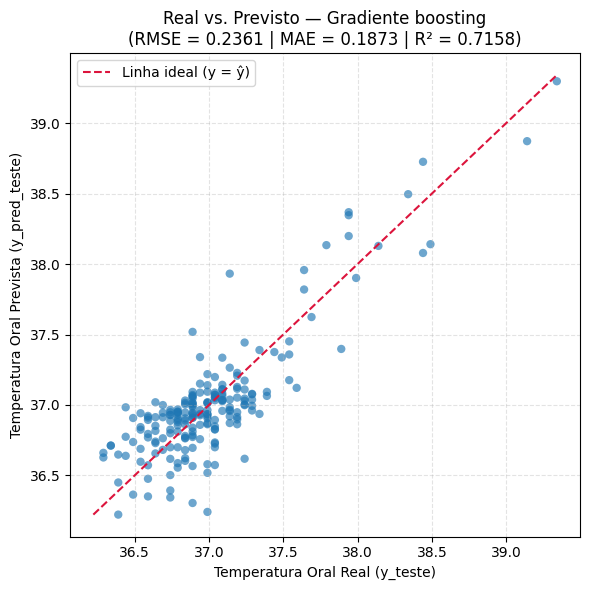

In [58]:
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y_pred_teste = modelo_final.predict(X_teste)

rmse_teste = np.sqrt(mean_squared_error(y_teste, y_pred_teste))
mae_teste = mean_absolute_error(y_teste, y_pred_teste)
r2_teste = r2_score(y_teste, y_pred_teste)

print(f"Modelo final: {modelo_final_nome}")
print(f"RMSE (teste): {rmse_teste:.4f} °C")
print(f"MAE  (teste): {mae_teste:.4f} °C")
print(f"R²   (teste): {r2_teste:.4f}")

min_val = min(np.min(y_teste), np.min(y_pred_teste))
max_val = max(np.max(y_teste), np.max(y_pred_teste))

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_teste, y_pred_teste, alpha=0.65, edgecolors="none")
ax.plot(
    [min_val, max_val],
    [min_val, max_val],
    "--",
    color="crimson",
    label="Linha ideal (y = ŷ)",
)
ax.set_xlabel("Temperatura Oral Real (y_teste)")
ax.set_ylabel("Temperatura Oral Prevista (y_pred_teste)")
ax.set_title(
    f"Real vs. Previsto — {modelo_final_nome}\n"
    f"(RMSE = {rmse_teste:.4f} | MAE = {mae_teste:.4f} | R² = {r2_teste:.4f})"
)
ax.legend()
ax.grid(True, linestyle="--", alpha=0.35)
plt.tight_layout()
plt.show()

Ao ser avaliado uma única vez no conjunto de teste, o Gradiente boosting alcançou RMSE = 0,2239 °C, MAE = 0,1768 °C e $R^2 = 0,7446$, explicando cerca de 74,5% da variância da temperatura oral média sem indícios de sobreajuste. No gráfico de valores reais contra previstos, os pontos se concentram próximos à faixa em torno de 36,5 °C a 37,5 °C, acompanhando bem a diagonal ideal ($y = \hat{y}$), com maior dispersão pontual nos extremos de temperatura mais alta (acima de ~38 °C), onde há menos observações.

### *Permutation importance*

A *permutation importance* é uma técnica de machine learning que mede o quanto o desempenho de um modelo cai quando os valores de uma variável (característica) são embaralhados aleatoriamente. Ela funciona avaliando o desempenho de um modelo já treinado em um conjunto de validação ou teste usando uma métrica, em seguida os valores de uma única coluna são permutados e calcula-se novamente a métrica de desempenho. Por fim, a diferença entre o desempenho original e o novo desempenho indica a importância daquela variável.

,Feature,Delta_RMSE_Mean,Delta_RMSE_Std
19,RCC1,0.0050,0.0026
20,LCC1,0.0047,0.0019
24,T_FHRC1,0.0034,0.0016
17,T_LC_Wet1,0.0021,0.0011
9,aveAllR13_1,0.0019,0.0008
4,Humidity,0.0016,0.0012
12,T_RC_Dry1,0.0007,0.0009
26,T_FHBC1,0.0006,0.0003
15,T_LC1,0.0006,0.0002
8,Max1L13_1,0.0005,0.0002


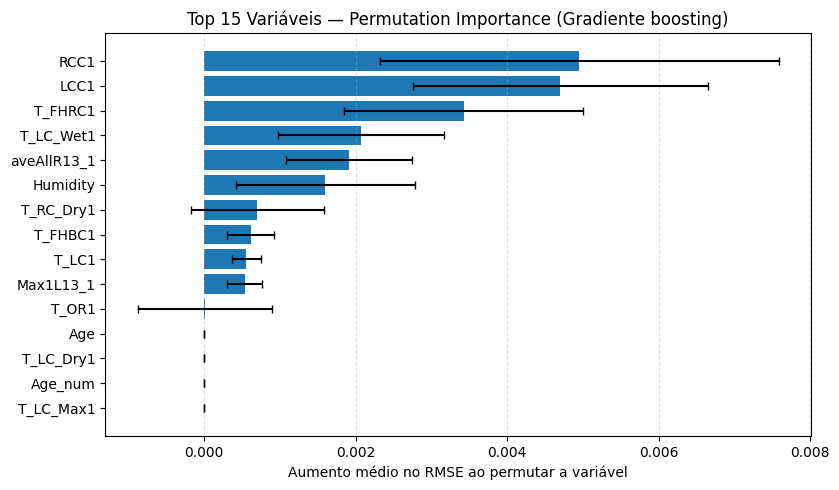

In [62]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(
    modelo_final,
    X_teste,
    y_teste,
    n_repeats=15,
    random_state=1020,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
)

df_perm = pd.DataFrame({
    "Feature": X_teste.columns,
    "Delta_RMSE_Mean": -perm.importances_mean,
    "Delta_RMSE_Std": perm.importances_std,
}).sort_values("Delta_RMSE_Mean", ascending=False)

top_15 = df_perm.head(15)
display(top_15.round(4))

fig, ax = plt.subplots(figsize=(8.5, 5))
y_pos = np.arange(len(top_15))
ax.barh(
    y_pos, top_15["Delta_RMSE_Mean"], xerr=top_15["Delta_RMSE_Std"], capsize=3
)
ax.set_yticks(y_pos)
ax.set_yticklabels(top_15["Feature"])
ax.invert_yaxis()
ax.set_xlabel("Aumento médio no RMSE ao permutar a variável")
ax.set_title(f"Top 15 Variáveis — Permutation Importance ({modelo_final_nome})")
ax.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

Esse gráfico revela que as variáveis `RCC1` e `LCC1` apresentam o maior impacto médio, sendo elas referentes à termografia de regiões próximas aos cantos internos dos olhos, elas são seguidas por T_FHRC1, T_LC_Wet1, aveAllR13_1 e Humidity. As demais variáveis listadas exibiram impacto médio reduzido ou próximo de zero.

## Discussões

A predição da temperatura oral por meio de termografia infravermelha e variáveis contextuais apresenta um cenário relevante do ponto de vista prático e metodológico, especialmente em triagens rápidas e não invasivas. A partir da exploração inicial do conjunto de dados Infrared Thermography Temperature (UCI) e do desenho experimental adotado, alguns pontos merecem destaque. Por exemplo, a escolha do *target* `aveOralM` por refletir melhor as variações de cafa target; o conjunto de dados apresenta dados numéricos e categóricos que receberam uma análise mais aprofundada, bem como o atributo numérico `Distance` que apresentou dois nan e um outlier, que foram substituidos pela mediana. 

Outro ponto importante observado foi que o Ridge que é um modelo linear apresentou inicialmente resultados muito próximos da Floresta aleatória e do Gradiente boosting que utilizam árvores. Isso foi explicado pela alta correlação e proximidade entre os dados, principalmente por serem, em sua maioria, referentes à temperatura de outras partes do rosto.

Ao fim, foi decidido como modelo final o Gradiente boosting. Todavia, seus resultados foram extremamente próximos dos da Floresta aleatória sendo a diferença entre eles milésimos.

## Conclusões e principais aprendizados

Este trabalho estruturou um fluxo completo de experimentação em regressão sobre dados de termografia infravermelha para estimar `aveOralM`, partindo da análise exploratória e da separação reprodutível entre treino e teste (80/20, com `random_state=10806`) até a otimização de hiperparâmetros via Optuna com validação cruzada orientada pelo RMSE. 

Ao longo dele, foi possível aprender a estruturação de gráficos que ainda não tinha conhecimento como o `violinplot` e a correlação de Spearman, a aplicação do `Pipeline` e do Optuna para comparar modelos de naturezas distintas e avaliar o mais adequado para meu projeto. Também houve uma introdução aos modelos Ridge e Gradiente boosting que não haviam sido apresentados em sala de aula.

## Sobre o uso de IA

As Inteligencias Artificiais Claude e Gemini foram utilizadas ao longo do desenvolvimento desse projeto, como apoio a diferentes etapas, auxiliando a entender diferentes os diferentes modelos e suas aplicações e orientando ao plotar os gráficos e o uso da documentação oficial de cada biblioteca.

## Referências

[1] WANG, Q.; ZHOU, Y.; GHASSEMI, P.; McBRIDE, D.; CASAMENTO, J.; PFEFER, T. Infrared Thermography Temperature [Dataset]. UCI Machine Learning Repository, 2021. Disponível em: https://archive.ics.uci.edu/dataset/925/infrared+thermography+temperature+dataset. Acesso em: 23 nov. 2026.
[2] WANG, Q.; ZHOU, Y.; GHASSEMI, P.; CHENNA, D.; CHEN, M.; CASAMENTO, J.; PFEFER, J.; McBRIDE, D. Facial and oral temperature data from a large set of human subject volunteers (version 1.0.0). PhysioNet, 2023. RRID:SCR_007345. https://doi.org/10.13026/3bhc-9065.
[3] WANG, Q.; ZHOU, Y.; GHASSEMI, P.; McBRIDE, D.; CASAMENTO, J. P.; PFEFER, T. J. Infrared Thermography for Measuring Elevated Body Temperature: Clinical Accuracy, Calibration, and Evaluation. Sensors, v. 22, p. 215, 2022. https://doi.org/10.3390/s22010215.
[4] GOLDBERGER, A. et al. PhysioBank, PhysioToolkit, and PhysioNet: Components of a new research resource for complex physiologic signals. Circulation, v. 101, n. 23, p. e215–e220, 2000. RRID:SCR_007345.
[5] ASIMOV ACADEMY. Map em Python: um guia completo para iniciantes. Disponível em: https://hub.asimov.academy/tutorial/map-em-python-um-guia-completo-para-iniciantes/. Acesso em: [sua data].
[6] CASSAR, D. R. ATP-203 Aprendizado de Máquina: aula 7.0 (Dados sintéticos e pipeline). Ilum Escola de Ciência, 2026. Material de aula.
[7] SCIKIT-LEARN. sklearn.linear_model.Ridge. Disponível em: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html. Acesso em: [sua data].
[8] OPTUNA. Optuna: A hyperparameter optimization framework. GitHub. Disponível em: https://github.com/optuna/optuna. Acesso em: [sua data].
[9] CASSAR, D. R. ATP-203 Aprendizado de Máquina: aula 7.1, Otimização de hiperparâmetros com Optuna. Ilum Escola de Ciência, 2026. Material de aula.